# Two-Phase Amyloid Core CNN Training

**Data split:** 70 % train / 30 % validation (stratified on class label).

| Phase | Data | What trains |
|-------|------|-------------|
| SSL (Phase 1) | resampled 70 % | SimCLR encoder (no labels in loss) |
| Classifier (Phase 2) | resampled 70 % | frozen encoder + linear head, validated on 30 % |

The 30 % set is a **held-out validation set** throughout — it receives no gradient updates.

Run from the `notebooks/` directory so relative paths (`../`) resolve to the project root.

## 1 — Setup & Imports

In [182]:
import os, sys, copy, json

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score

sys.path.insert(0, os.path.abspath(".."))

from src.data import build_dataset, DEFAULT_MAX_LEN, pad_to
from src.esm_embed import EMBED_DIM, embed_batch   # EMBED_DIM = 480
from src.flexible_cnn import FlexibleCNN

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


## 2 — Data Loading

In [183]:
POS_PATH = "../New_dataset/Training/train_core_set_KA.json"
NEG_PATH = "../New_dataset/Training/new_negative.json"

print("Loading dataset (uses ESM2 embedding cache) ...")
X, y = build_dataset(POS_PATH, NEG_PATH, max_len=DEFAULT_MAX_LEN, use_cache=True)

n_pos, n_neg = int(y.sum()), int((y == 0).sum())
print(f"X : {X.shape}  dtype={X.dtype}")
print(f"y : {y.shape}  dtype={y.dtype}")
print(f"Positives : {n_pos}  |  Negatives : {n_neg}  |  ratio : {n_neg/n_pos:.1f}:1")

Loading dataset (uses ESM2 embedding cache) ...
X : (1808, 480, 20)  dtype=float32
y : (1808,)  dtype=int64
Positives : 157  |  Negatives : 1651  |  ratio : 10.5:1


## 3 — 70 / 30 Stratified Split

70 % is used for training (SSL + classifier head). 30 % is the held-out validation set.

In [184]:
idx_tr, idx_ft = train_test_split(
    np.arange(len(y)), test_size=0.30, stratify=y, random_state=SEED
)

X_tr, y_tr = X[idx_tr], y[idx_tr]   # 70 % — encoder + initial classifier
X_ft, y_ft = X[idx_ft], y[idx_ft]   # 30 % — held-out validation

print(f"Train (70 %) : {len(y_tr):4d} samples | pos={y_tr.sum():3d}  neg={(y_tr==0).sum():4d}")
print(f"Val     (30 %) : {len(y_ft):4d} samples | pos={y_ft.sum():3d}  neg={(y_ft==0).sum():4d}")

Train (70 %) : 1265 samples | pos=110  neg=1155
Val     (30 %) :  543 samples | pos= 47  neg= 496


## 4 — Over / Under Sampling within the 70 % Training Set

Target ratio ≈ **1:2** (pos:neg).

* **Over-sample positives 2×** — original + one noisy copy (Gaussian σ=0.05).
* **Under-sample negatives** to `2 × n_pos_aug`.

The resampled set (`X_res`, `y_res`) is used for both Phase 1 (SSL) and Phase 2 (classifier).

In [185]:
rng = np.random.default_rng(SEED)

X_pos = X_tr[y_tr == 1]    # (n_pos, 480, 20)
X_neg = X_tr[y_tr == 0]    # (n_neg, 480, 20)

# Oversample: original + noisy copy
noise     = rng.normal(0.0, 0.05, X_pos.shape).astype(np.float32)
X_pos_aug = np.concatenate([X_pos, X_pos + noise], axis=0)   # 2 × n_pos
y_pos_aug = np.ones(len(X_pos_aug), dtype=np.int64)

# Undersample negatives to 2 × n_pos_aug  →  1:2 ratio
neg_sel   = rng.choice(len(X_neg), size=len(X_pos_aug) * 2, replace=False)
X_neg_sub = X_neg[neg_sel]
y_neg_sub = np.zeros(len(X_neg_sub), dtype=np.int64)

X_res = np.concatenate([X_pos_aug, X_neg_sub], axis=0)
y_res = np.concatenate([y_pos_aug, y_neg_sub], axis=0)
perm  = rng.permutation(len(X_res))
X_res, y_res = X_res[perm], y_res[perm]

print(f"Resampled train set : {X_res.shape}")
print(f"  positives (aug)   : {int(y_res.sum())}")
print(f"  negatives (sub)   : {int((y_res==0).sum())}")
print(f"  ratio (neg:pos)   : {int((y_res==0).sum())/max(int(y_res.sum()),1):.1f}:1")

Resampled train set : (660, 480, 20)
  positives (aug)   : 220
  negatives (sub)   : 440
  ratio (neg:pos)   : 2.0:1


## 5 — Phase 1: SimCLR Self-Supervised Encoder Training

The encoder trains on **all of `X_tr`** (full 70 %, 1265 samples — all negatives included).
Labels are never used in the NT-Xent loss, so class imbalance is irrelevant here.
The resampled set `X_res` is used only for the supervised classifier head in Phase 2.

### 5a — Augmentation Functions

In [186]:
def random_mask(x: torch.Tensor, p: float = 0.10) -> torch.Tensor:
    """Zero out random position columns. x: (480, 20) -> (480, 20)."""
    mask = torch.rand(x.shape[1], device=x.device) < p
    out  = x.clone()
    out[:, mask] = 0.0
    return out


def add_noise(x: torch.Tensor, std: float = 0.05) -> torch.Tensor:
    """Add Gaussian noise. x: (480, 20) -> (480, 20)."""
    return x + torch.randn_like(x) * std


def augment(x: torch.Tensor) -> torch.Tensor:
    """Randomly apply masking, noise, or both."""
    r = torch.rand(1).item()
    if r < 0.33:
        return random_mask(x)
    elif r < 0.67:
        return add_noise(x)
    else:
        return add_noise(random_mask(x))

### 5b — SimCLR Dataset

In [187]:
class SimCLRDataset(Dataset):
    """Returns two independently augmented views of the same sample. Labels ignored."""

    def __init__(self, X: np.ndarray):
        self.X = torch.from_numpy(X)   # (N, 480, 20)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]                # (480, 20)
        return augment(x), augment(x)  # two independent views

### 5c — Encoder and Projection Head

In [198]:
CNN_CONFIG = dict(
    in_channels=EMBED_DIM,    # 480
    conv_channels=(256,),
    kernel_sizes=(3,5),
    pool="maxmean",
    batchnorm=True,
    activation="relu",
    dropout=0,
)
_tmp    = FlexibleCNN(**CNN_CONFIG)
ENC_DIM = CNN_CONFIG["conv_channels"][-1] * _tmp.pool.out_multiplier()
del _tmp
# pool='max'/'mean' → ×1 ;  pool='maxmean' → ×2 (max + mean concatenated)


class SimCLREncoder(nn.Module):
    """FlexibleCNN backbone (features + pool), no head.

    Forward: (B, 480, 20) -> (B, ENC_DIM)
    """

    def __init__(self, cnn_config: dict):
        super().__init__()
        _full         = FlexibleCNN(**cnn_config)
        self.features = _full.features
        self.pool     = _full.pool

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.pool(self.features(x))   # (B, ENC_DIM)


class ProjectionHead(nn.Module):
    """MLP projection: enc_dim -> 128 -> 64. Discarded after SSL."""

    def __init__(self, enc_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(enc_dim, 128), nn.ReLU(),
            nn.Linear(128, 64),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)   # (B, 64)


encoder   = SimCLREncoder(CNN_CONFIG).to(DEVICE)
proj_head = ProjectionHead(ENC_DIM).to(DEVICE)
print(f"ENC_DIM           : {ENC_DIM}")
print(f"Encoder params    : {sum(p.numel() for p in encoder.parameters()):,}")
print(f"Proj-head params  : {sum(p.numel() for p in proj_head.parameters()):,}")

ENC_DIM           : 512
Encoder params    : 492,288
Proj-head params  : 73,920


### 5d — NT-Xent Loss

$$
\mathcal{L} = -\frac{1}{2B}\sum_{i=1}^{2B}\log
\frac{\exp(\text{sim}(z_i,z_{j(i)})/\tau)}{\sum_{k\neq i}\exp(\text{sim}(z_i,z_k)/\tau)}
$$

In [199]:
def nt_xent_loss(z1: torch.Tensor, z2: torch.Tensor, temperature: float = 0.5) -> torch.Tensor:
    B   = z1.shape[0]
    z   = F.normalize(torch.cat([z1, z2], dim=0), dim=1)   # (2B, D)
    sim = torch.mm(z, z.T) / temperature                    # (2B, 2B)
    sim = sim.masked_fill(torch.eye(2*B, dtype=torch.bool, device=z.device), float("-inf"))
    labels = torch.cat([
        torch.arange(B, 2*B, device=z.device),
        torch.arange(0,   B, device=z.device),
    ])
    return F.cross_entropy(sim, labels)

### 5e — Phase 1 Training Loop

In [200]:
SSL_EPOCHS   = 100
SSL_LR       = 1e-3
SSL_BATCH    = 16
ENCODER_PATH = "../models/simclr_encoder.pt"

ssl_loader = DataLoader(
    SimCLRDataset(X_tr), batch_size=SSL_BATCH, shuffle=True, drop_last=True
)
print(f"SSL batches/epoch: {len(ssl_loader)}  (full 70 % train set, drop_last)")

ssl_opt = torch.optim.Adam(
    list(encoder.parameters()) + list(proj_head.parameters()),
    lr=SSL_LR, weight_decay=1e-4,
)

for epoch in range(1, SSL_EPOCHS + 1):
    encoder.train(); proj_head.train()
    total = 0.0
    for x1, x2 in ssl_loader:
        x1, x2 = x1.to(DEVICE), x2.to(DEVICE)
        z1 = proj_head(encoder(x1))
        z2 = proj_head(encoder(x2))
        loss = nt_xent_loss(z1, z2)
        ssl_opt.zero_grad(); loss.backward(); ssl_opt.step()
        total += loss.item()
    if epoch == 1 or epoch % 10 == 0:
        print(f"SSL  [{epoch:3d}/{SSL_EPOCHS}]  NT-Xent: {total/len(ssl_loader):.4f}")

os.makedirs("../models", exist_ok=True)
torch.save({"encoder_state_dict": encoder.state_dict(),
            "cnn_config": CNN_CONFIG, "enc_dim": ENC_DIM}, ENCODER_PATH)
print(f"Encoder saved -> {ENCODER_PATH}")

SSL batches/epoch: 79  (full 70 % train set, drop_last)
SSL  [  1/100]  NT-Xent: 1.8370
SSL  [ 10/100]  NT-Xent: 1.6468
SSL  [ 20/100]  NT-Xent: 1.6292
SSL  [ 30/100]  NT-Xent: 1.6250
SSL  [ 40/100]  NT-Xent: 1.6094
SSL  [ 50/100]  NT-Xent: 1.6066
SSL  [ 60/100]  NT-Xent: 1.6035
SSL  [ 70/100]  NT-Xent: 1.5997
SSL  [ 80/100]  NT-Xent: 1.5962
SSL  [ 90/100]  NT-Xent: 1.5935
SSL  [100/100]  NT-Xent: 1.5937
Encoder saved -> ../models/simclr_encoder.pt


## 6 — Phase 2: Classifier Training on Resampled 70 %

The SSL encoder is **frozen**. A `Linear(ENC_DIM → 1)` head is trained on the resampled 70 % set.
The 30 % split is used as a **held-out validation set** only — no gradient updates on it.

### 6a — Classifier Model

In [201]:
class AmyloidClassifier(nn.Module):
    """Frozen encoder + binary head.  Forward: (B,480,20) -> logits (B,)."""

    def __init__(self, encoder: SimCLREncoder, enc_dim: int, freeze_encoder: bool = True):
        super().__init__()
        self.encoder = encoder
        self.head    = nn.Linear(enc_dim, 1)
        
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.encoder(x)).squeeze(-1)   # (B,)

### 6b — Shared Utilities: Loss and Eval

In [202]:
LABEL_SMOOTH_EPS = 0.10

def bce_smooth_loss(logits: torch.Tensor, y: torch.Tensor,
                    eps: float = LABEL_SMOOTH_EPS) -> torch.Tensor:
    """BCE with label smoothing: {0,1} -> {eps/2, 1-eps/2}."""
    return F.binary_cross_entropy_with_logits(logits, y * (1 - eps) + eps / 2.0)


@torch.no_grad()
def evaluate(model, loader) -> dict:
    model.eval()
    probs_all, true_all = [], []
    for xb, yb in loader:
        probs_all.append(torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy())
        true_all.append(yb.numpy())
    probs = np.concatenate(probs_all)
    true  = np.concatenate(true_all).astype(int)
    preds = (probs >= 0.5).astype(int)
    return {
        "f1"       : f1_score(true, preds, zero_division=0),
        "auc"      : roc_auc_score(true, probs) if len(np.unique(true)) > 1 else float("nan"),
        "precision": precision_score(true, preds, zero_division=0),
        "recall"   : recall_score(true, preds, zero_division=0),
    }


def make_loader(X: np.ndarray, y: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y.astype(np.float32)))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

### 6c — Phase 2: K-Fold CV + Final Model

In [212]:
from sklearn.model_selection import StratifiedKFold

K_FOLDS         = 5
P2_EPOCHS       = 30
P2_LR           = 1e-3
P2_BATCH        = 32
CLASSIFIER_PATH = "../models/amyloid_classifier.pt"

ckpt_ssl = torch.load(ENCODER_PATH, map_location=DEVICE)


def _resample(X_pos, X_neg, rng):
    """Oversample pos 2x + undersample neg to 2x pos."""
    noise     = rng.normal(0.0, 0.05, X_pos.shape).astype(np.float32)
    X_pos_aug = np.concatenate([X_pos, X_pos + noise])
    y_pos_aug = np.ones(len(X_pos_aug), dtype=np.int64)
    n_sel     = min(len(X_pos_aug) * 2, len(X_neg))
    sel       = rng.choice(len(X_neg), size=n_sel, replace=False)
    X_neg_sub = X_neg[sel]
    y_neg_sub = np.zeros(n_sel, dtype=np.int64)
    X_out     = np.concatenate([X_pos_aug, X_neg_sub])
    y_out     = np.concatenate([y_pos_aug, y_neg_sub])
    perm      = rng.permutation(len(X_out))
    return X_out[perm], y_out[perm]


# ── K-Fold CV on the 70 % set ─────────────────────────────────────────────────
skf            = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
fold_metrics   = []
fold_histories = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr), 1):
    print(f"\n── Fold {fold}/{K_FOLDS}  "
          f"(train={len(tr_idx)}, val={len(val_idx)}) ──")

    X_f_tr,  y_f_tr  = X_tr[tr_idx],  y_tr[tr_idx]
    X_f_val, y_f_val = X_tr[val_idx], y_tr[val_idx]

    # Resample training split only — val split stays original (no leakage)
    fold_rng         = np.random.default_rng(SEED + fold)
    X_f_res, y_f_res = _resample(X_f_tr[y_f_tr == 1],
                                  X_f_tr[y_f_tr == 0], fold_rng)

    enc_f = SimCLREncoder(ckpt_ssl["cnn_config"]).to(DEVICE)
    enc_f.load_state_dict(ckpt_ssl["encoder_state_dict"])
    clf_f = AmyloidClassifier(enc_f, enc_dim=ckpt_ssl["enc_dim"],
                               freeze_encoder=True).to(DEVICE)

    tr_ldr  = make_loader(X_f_res, y_f_res, P2_BATCH, shuffle=True)
    val_ldr = make_loader(X_f_val, y_f_val, 256,      shuffle=False)
    opt_f   = torch.optim.Adam(
        filter(lambda p: p.requires_grad, clf_f.parameters()),
        lr=P2_LR, weight_decay=1e-3,
    )
    sched_f = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt_f, mode="max", factor=0.5, patience=5, min_lr=1e-5,
    )

    hist_f    = {"train_loss": [], "val_f1": [], "val_auc": [], "lr": []}
    best_f1_f = -1.0

    for epoch in range(1, P2_EPOCHS + 1):
        clf_f.train()
        total = 0.0
        for xb, yb in tr_ldr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss   = bce_smooth_loss(clf_f(xb), yb)
            opt_f.zero_grad(); loss.backward(); opt_f.step()
            total += loss.item()
        avg_loss = total / len(tr_ldr)
        m        = evaluate(clf_f, val_ldr)
        hist_f["train_loss"].append(avg_loss)
        hist_f["val_f1"].append(m["f1"])
        hist_f["val_auc"].append(m["auc"])
        hist_f["lr"].append(opt_f.param_groups[0]["lr"])
        sched_f.step(m["f1"])
        if m["f1"] > best_f1_f:
            best_f1_f = m["f1"]

    fold_metrics.append({"f1":  best_f1_f,
                          "auc": float(np.nanmax(hist_f["val_auc"]))})
    fold_histories.append(hist_f)
    print(f"  best val F1 {best_f1_f:.3f}  |  best val AUC {fold_metrics[-1]['auc']:.3f}")

mean_f1  = float(np.mean([m["f1"]  for m in fold_metrics]))
std_f1   = float(np.std( [m["f1"]  for m in fold_metrics]))
mean_auc = float(np.mean([m["auc"] for m in fold_metrics]))
std_auc  = float(np.std( [m["auc"] for m in fold_metrics]))
print(f"\n{'='*44}")
print(f"  {K_FOLDS}-Fold CV   "
      f"F1  {mean_f1:.3f} ± {std_f1:.3f}   "
      f"AUC  {mean_auc:.3f} ± {std_auc:.3f}")
print(f"{'='*44}")

# ── Final model: retrain on all resampled 70 % ───────────────────────────────
print("\nRetraining final model on all resampled 70 % ...")
enc_final  = SimCLREncoder(ckpt_ssl["cnn_config"]).to(DEVICE)
enc_final.load_state_dict(ckpt_ssl["encoder_state_dict"])
classifier = AmyloidClassifier(enc_final, enc_dim=ckpt_ssl["enc_dim"],
                                freeze_encoder=True).to(DEVICE)
res_loader = make_loader(X_res, y_res, P2_BATCH, shuffle=True)
val_loader = make_loader(X_ft,  y_ft,  256,      shuffle=False)
opt_final   = torch.optim.Adam(
    filter(lambda p: p.requires_grad, classifier.parameters()),
    lr=P2_LR, weight_decay=1e-3,
)
sched_final = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt_final, mode="max", factor=0.5, patience=5, min_lr=1e-5,
)

history   = {"train_loss": [], "val_f1": [], "val_auc": [], "lr": []}
best_f1, best_state = -1.0, None

for epoch in range(1, P2_EPOCHS + 1):
    classifier.train()
    total = 0.0
    for xb, yb in res_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        loss   = bce_smooth_loss(classifier(xb), yb)
        opt_final.zero_grad(); loss.backward(); opt_final.step()
        total += loss.item()
    avg_loss = total / len(res_loader)
    m        = evaluate(classifier, val_loader)
    history["train_loss"].append(avg_loss)
    history["val_f1"].append(m["f1"])
    history["val_auc"].append(m["auc"])
    history["lr"].append(opt_final.param_groups[0]["lr"])
    sched_final.step(m["f1"])
    if epoch == 1 or epoch % 10 == 0:
        print(f"  [{epoch:3d}/{P2_EPOCHS}]  loss {avg_loss:.4f}  "
              f"val-F1 {m['f1']:.3f}  val-AUC {m['auc']:.3f}  "
              f"lr {opt_final.param_groups[0]['lr']:.2e}")
    if m["f1"] > best_f1:
        best_f1    = m["f1"]
        best_state = copy.deepcopy({k: v.cpu()
                                    for k, v in classifier.state_dict().items()})

classifier.load_state_dict(best_state)
os.makedirs("../models", exist_ok=True)
torch.save({
    "state_dict"      : classifier.state_dict(),
    "cnn_config"      : CNN_CONFIG,
    "enc_dim"         : ENC_DIM,
    "label_smooth_eps": LABEL_SMOOTH_EPS,
    "best_val_f1"     : best_f1,
    "cv_mean_f1"      : mean_f1,
    "cv_std_f1"       : std_f1,
    "history"         : history,
    "fold_histories"  : fold_histories,
}, CLASSIFIER_PATH)
print(f"\nFinal hold-out F1: {best_f1:.3f}  ->  saved {CLASSIFIER_PATH}")



── Fold 1/5  (train=1012, val=253) ──
  best val F1 0.407  |  best val AUC 0.837

── Fold 2/5  (train=1012, val=253) ──
  best val F1 0.519  |  best val AUC 0.898

── Fold 3/5  (train=1012, val=253) ──
  best val F1 0.345  |  best val AUC 0.829

── Fold 4/5  (train=1012, val=253) ──
  best val F1 0.578  |  best val AUC 0.896

── Fold 5/5  (train=1012, val=253) ──
  best val F1 0.436  |  best val AUC 0.853

  5-Fold CV   F1  0.457 ± 0.082   AUC  0.863 ± 0.029

Retraining final model on all resampled 70 % ...
  [  1/30]  loss 0.5999  val-F1 0.340  val-AUC 0.808  lr 1.00e-03
  [ 10/30]  loss 0.4591  val-F1 0.427  val-AUC 0.867  lr 1.00e-03
  [ 20/30]  loss 0.4357  val-F1 0.429  val-AUC 0.868  lr 5.00e-04
  [ 30/30]  loss 0.4305  val-F1 0.427  val-AUC 0.869  lr 1.25e-04

Final hold-out F1: 0.488  ->  saved ../models/amyloid_classifier.pt


## 7 — Evaluation

### 7a — 30 % Hold-Out Validation Metrics

In [213]:
print("=== 30 % hold-out validation ===")
m_val = evaluate(classifier, val_loader)
for k, v in m_val.items():
    print(f"  {k:<12}: {v:.4f}")

=== 30 % hold-out validation ===
  f1          : 0.4882
  auc         : 0.8659
  precision   : 0.3875
  recall      : 0.6596


### 7b — Benchmark Sliding Window (optional)

> **Note:** ESM2 is run **live** (no cache) for each window. 28 proteins × ~100–300 residues = several minutes on CPU.

In [214]:
from src.predict import core_mask, longest_positive_run

BENCHMARK_PATH = "../New_dataset/Benchmark/new_representative_classification_benchmark_KA.json"


@torch.no_grad()
def score_protein(seq: str, model, k: int = 7,
                  max_len: int = DEFAULT_MAX_LEN, batch_size: int = 128) -> np.ndarray:
    L       = len(seq)
    windows = [seq[max(0, i - k): i + k + 1] for i in range(L)]
    embs    = embed_batch(windows, use_cache=False, batch_size=batch_size)
    X_w     = np.stack([pad_to(e.numpy().astype(np.float32), max_len) for e in embs])
    model.eval()
    probs = []
    for s in range(0, len(X_w), batch_size):
        xb = torch.from_numpy(X_w[s: s + batch_size]).to(DEVICE)
        probs.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(probs)   # (L,)


with open(BENCHMARK_PATH) as f:
    benchmark = json.load(f)

res_true_all, res_prob_all, prot_true, prot_pred = [], [], [], []
for prot in benchmark:
    prob = score_protein(prot["Sequence"], classifier)
    mask = core_mask(prot)
    res_true_all.append(mask)
    res_prob_all.append(prob)
    run = longest_positive_run(prob >= 0.5)
    prot_pred.append(1 if run >= 5 else 0)
    prot_true.append(1 if prot["LABEL"] == "AMYLOID" else 0)

rt    = np.concatenate(res_true_all)
rp    = np.concatenate(res_prob_all)
rpred = (rp >= 0.5).astype(int)
pt, pp = np.array(prot_true), np.array(prot_pred)

print("=== Residue-level (28 benchmark proteins) ===")
print(f"  Precision : {precision_score(rt, rpred, zero_division=0):.3f}")
print(f"  Recall    : {recall_score(rt, rpred, zero_division=0):.3f}")
print(f"  F1        : {f1_score(rt, rpred, zero_division=0):.3f}")
if len(np.unique(rt)) > 1:
    print(f"  AUC       : {roc_auc_score(rt, rp):.3f}")

print("\n=== Protein-level (AMYLOID vs NONAMYLOID) ===")
print(f"  Accuracy  : {(pt==pp).mean():.3f}  ({int((pt==pp).sum())}/{len(pt)})")
print(f"  Precision : {precision_score(pt, pp, zero_division=0):.3f}")
print(f"  Recall    : {recall_score(pt, pp, zero_division=0):.3f}")
print(f"  F1        : {f1_score(pt, pp, zero_division=0):.3f}")

=== Residue-level (28 benchmark proteins) ===
  Precision : 0.171
  Recall    : 0.383
  F1        : 0.236
  AUC       : 0.713

=== Protein-level (AMYLOID vs NONAMYLOID) ===
  Accuracy  : 0.750  (21/28)
  Precision : 0.667
  Recall    : 1.000
  F1        : 0.800


## 8 — Visualisations

Learning curve (per-fold CV + final model) and confusion matrices.
Run after cell 7b to include benchmark plots.

NameError: name 'fold_histories' is not defined

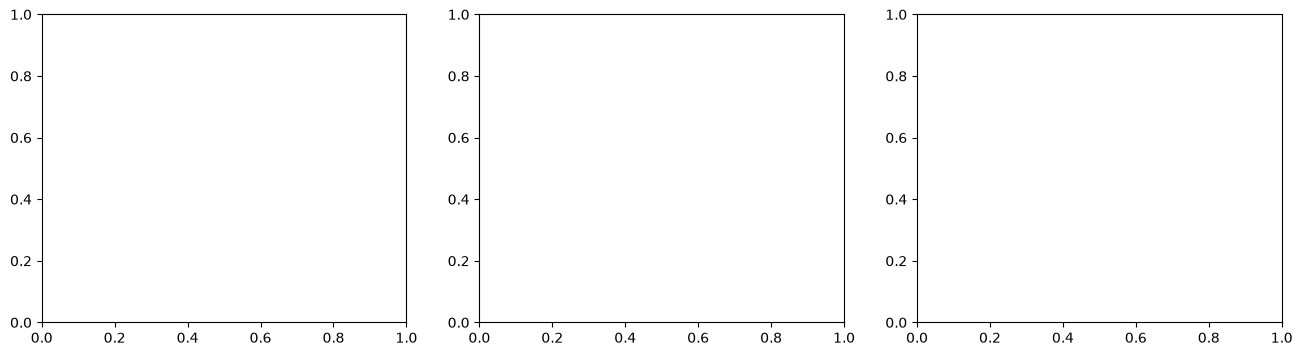

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# ── 1  Learning Curves ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors    = plt.cm.tab10.colors

# (a) Per-fold val F1 with mean ± std band
ax    = axes[0]
n_ep  = len(fold_histories[0]["val_f1"])
ep    = np.arange(1, n_ep + 1)
f1mat = np.array([h["val_f1"] for h in fold_histories])  # (K, epochs)
for k, h in enumerate(fold_histories):
    ax.plot(ep, h["val_f1"], color=colors[k], alpha=0.55,
            linewidth=1, label=f"Fold {k+1}")
mu, sigma = f1mat.mean(axis=0), f1mat.std(axis=0)
ax.plot(ep, mu, "k-", linewidth=2, label="Mean")
ax.fill_between(ep, mu - sigma, mu + sigma, alpha=0.15, color="black")
ax.set_xlabel("Epoch"); ax.set_ylabel("Val F1")
ax.set_title(f"{len(fold_histories)}-Fold CV — Val F1")
ax.legend(fontsize=7); ax.grid(alpha=0.3); ax.set_ylim(0, 1)

# (b) Final model training loss
ax     = axes[1]
ep_fin = np.arange(1, len(history["train_loss"]) + 1)
ax.plot(ep_fin, history["train_loss"], color="steelblue", linewidth=1.5)
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss (label-smoothed)")
ax.set_title("Final Model — Training Loss"); ax.grid(alpha=0.3)

# (c) Final model val F1 + AUC on 30 % hold-out
ax = axes[2]
ax.plot(ep_fin, history["val_f1"],  color="darkorange", linewidth=1.5, label="Val F1")
ax.plot(ep_fin, history["val_auc"], color="seagreen",   linewidth=1.5,
        linestyle="--", label="Val AUC")
best_ep = int(np.argmax(history["val_f1"])) + 1
ax.axvline(best_ep, color="red", linestyle=":", linewidth=1,
           label=f"Best (ep {best_ep})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Score")
ax.set_title("Final Model — 30 % Hold-Out")
ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(0, 1)

plt.suptitle(
    f"Learning Curves  |  {len(fold_histories)}-Fold CV: "
    f"F1 {mean_f1:.3f} ± {std_f1:.3f}   AUC {mean_auc:.3f} ± {std_auc:.3f}",
    fontsize=12, fontweight="bold",
)
plt.tight_layout()
plt.savefig("../models/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 2  Confusion Matrix — 30 % Hold-Out ──────────────────────────────────────
@torch.no_grad()
def get_preds(model, loader):
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        probs.append(torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy())
        labels.append(yb.numpy())
    p = np.concatenate(probs); y = np.concatenate(labels).astype(int)
    return y, (p >= 0.5).astype(int)

y_true_val, y_pred_val = get_preds(classifier, val_loader)

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_true_val, y_pred_val),
    display_labels=["Non-amyloid", "Amyloid"],
).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("30 % Hold-Out — Peptide Level", fontweight="bold")
plt.tight_layout()
plt.savefig("../models/cm_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 3  Confusion Matrices — Benchmark (requires cell 7b) ─────────────────────
try:
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    ConfusionMatrixDisplay(
        confusion_matrix(rt, rpred),
        display_labels=["Non-core", "Core"],
    ).plot(ax=axes[0], colorbar=False, cmap="Oranges")
    axes[0].set_title("Benchmark — Residue Level", fontweight="bold")

    ConfusionMatrixDisplay(
        confusion_matrix(pt, pp),
        
        display_labels=["Non-amyloid", "Amyloid"],
    ).plot(ax=axes[1], colorbar=False, cmap="Greens")
    axes[1].set_title("Benchmark — Protein Level", fontweight="bold")

    plt.tight_layout()
    plt.savefig("../models/cm_benchmark.png", dpi=150, bbox_inches="tight")
    plt.show()
except NameError:
    print("Run cell 7b (benchmark sliding window) first for benchmark confusion matrices.")
